<a href="https://colab.research.google.com/github/InahH-004/PCD_Collage/blob/main/3th_Assigment/PCD_Assignment03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [74]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files

#Import Image

Saving lubang-jalan.jpeg to lubang-jalan (5).jpeg


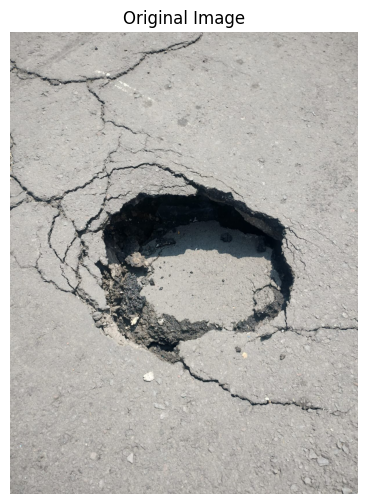

Image shape: (1600, 1204, 3)


In [75]:
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

image = Image.open(image_path).convert('RGB')
image = np.array(image)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.show()

print("Image shape:", image.shape)

# Ubah ke Grayscale

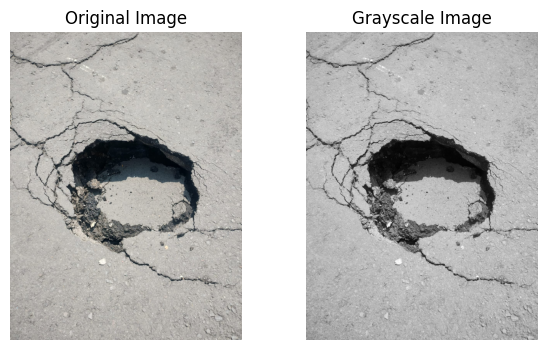

In [76]:
def grayscale_conversion(image):
    height, width, _ = image.shape

    gray = np.zeros((height, width), dtype=np.uint8)

    for i in range(height):
        for j in range(width):
            r, g, b = image[i, j]

            gray[i, j] = int(
                0.299 * r +
                0.587 * g +
                0.114 * b
            )

    return gray


gray_image = grayscale_conversion(image)

plt.figure(figsize=(7, 4))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray_image, cmap='gray')
plt.title("Grayscale Image")
plt.axis("off")

plt.show()

# Menentukan Threshold dengan Otsu

In [77]:
def otsu_threshold(gray):
    # Bikin histogram: hist[i] = jumlah piksel dengan intensitas i
    hist = [0] * 256
    for row in gray:
        for p in row:
            hist[p] += 1

    total = sum(hist)                              # total jumlah piksel
    sum_all = sum(i * hist[i] for i in range(256)) # jumlah total intensitas

    w_b = 0        # bobot kelas background (piksel <= t)
    sum_b = 0.0    # jumlah intensitas kelas background
    best_var = -1.0
    best_t = 0

    # Cari dengan coba setiap kemungkinan threshold t
    for t in range(256):
        w_b += hist[t]
        if w_b == 0:
            continue                # belum ada piksel di kelas background
        w_f = total - w_b           # bobot kelas foreground (piksel > t)
        if w_f == 0:
            break                   # semua piksel sudah masuk background

        sum_b += t * hist[t]
        m_b = sum_b / w_b                   # rata-rata intensitas background
        m_f = (sum_all - sum_b) / w_f       # rata-rata intensitas foreground

        # Variansi antar-kelas: semakin besar, semakin baik pemisahannya
        between = w_b * w_f * (m_b - m_f) ** 2

        if between > best_var:
            best_var = between
            best_t = t

    return best_t

#Jalankan threshold
threshold = otsu_threshold(gray_image)

print("Otsu Threshold:", threshold)

Otsu Threshold: 114


# Segmentasi Berdasarkan Threshold

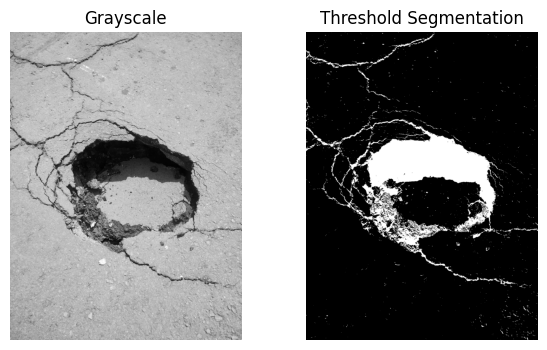

In [78]:
#Buat segmentasinya berdasrkan threshold

def threshold_segmentation(image, threshold, invert=True): #pada citra yang terang, sebaiknya segmentasinya di invert (True) agar lebih terlihat

    height, width = image.shape #inisiasi ukuran

    binary = np.zeros((height, width), dtype=np.uint8) #inisiasi hasil segmentasi dengan nilai 0

    for i in range(height):
        for j in range(width):

            if image[i, j] > threshold: #segmentasi berdasarkan threshold
                binary[i, j] = 255

            else:
                binary[i, j] = 0

    if invert: #Ubah segmentasi citra dari terang ke gelap / gelap ke terang
        binary = 255 - binary

    return binary


#Jalankan segmentasi
segmented_image = threshold_segmentation(
    gray_image,
    threshold
)

plt.figure(figsize=(7, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap='gray')
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(segmented_image, cmap='gray')
plt.title("Threshold Segmentation")
plt.axis("off")

plt.show()

#Implementasi Morphological Operations

In [79]:
# Structuring element 3x3 (kernel)
structuring_element = np.ones((3, 3), dtype=np.uint8)

print(structuring_element)

[[1 1 1]
 [1 1 1]
 [1 1 1]]


## Erosi

Prinsip erosion:
- Pixel tengah akan menjadi putih jika seluruh pixel pada area structuring element bernilai putih.
- Jika terdapat setidaknya satu pixel hitam, pixel tengah menjadi hitam

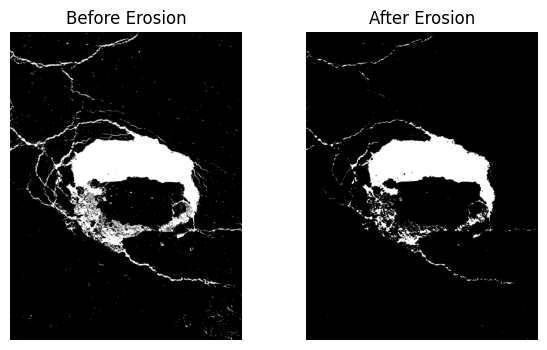

In [80]:
def erosion(image, kernel):

    height, width = image.shape
    k_height, k_width = kernel.shape

    pad_h = k_height // 2
    pad_w = k_width // 2

    padded = np.pad( #menambahkan padding pada image
        image,
        ((pad_h, pad_h), (pad_w, pad_w)),
        mode='constant',
        constant_values=0
    )

    result = np.zeros_like(image) #inisiasi hasil dengan 0

    for i in range(height):
        for j in range(width):

            # ambil area tetangga sesuai ukuran kernel
            region = padded[
                i:i+k_height,
                j:j+k_width
            ]

            #periksa apakah SELURUH piksel yang digunakan kernel bernilai 255
            if np.all(region[kernel == 1] == 255):

                #jika ya, berarti piksel tengah putih (255)
                result[i, j] = 255
            else: #jika tidak (ada minimal 1 bukan putih), berarti hitam (0)
                result[i, j] = 0

    return result


#Panggil fungsi erosi
eroded_image = erosion(
    segmented_image,
    structuring_element
)

plt.figure(figsize=(7, 4))

plt.subplot(1, 2, 1)
plt.imshow(segmented_image, cmap='gray')
plt.title("Before Erosion")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(eroded_image, cmap='gray')
plt.title("After Erosion")
plt.axis("off")

plt.show()

## Dilatasi

Syaratnya: cukup terdapat satu pixel putih pada area structuring element agar pixel tengah menjadi putih.

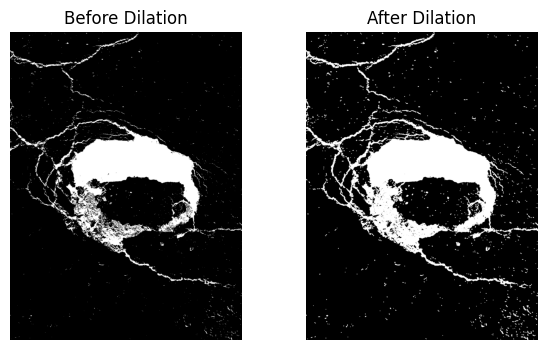

In [81]:
def dilation(image, kernel):

    height, width = image.shape
    k_height, k_width = kernel.shape

    pad_h = k_height // 2
    pad_w = k_width // 2

    padded = np.pad(
        image,
        ((pad_h, pad_h), (pad_w, pad_w)),
        mode='constant',
        constant_values=0
    )

    result = np.zeros_like(image)

    for i in range(height):
        for j in range(width):

            region = padded[
                i:i+k_height,
                j:j+k_width
            ]

            #cek apakah ada minimal satu warna putih
            if np.any(region[kernel == 1] == 255):

                #jika iya, berarti piksel tengahnya putih (255)
                result[i, j] = 255
            else: #jika tidak (semuanya warna hitam), maka piksel tengahnya hitam
                result[i, j] = 0

    return result


dilated_image = dilation(
    segmented_image,
    structuring_element
)

plt.figure(figsize=(7, 4))

plt.subplot(1, 2, 1)
plt.imshow(segmented_image, cmap='gray')
plt.title("Before Dilation")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(dilated_image, cmap='gray')
plt.title("After Dilation")
plt.axis("off")

plt.show()

Perbedaannya dengan erosion:
- Erosion menggunakan np.all().
- Dilation menggunakan np.any().

## Opening

Opening merupakan kombinasi dari erosion yang dilanjutkan dengan dilation.
Tujuan utamanya adalah menghilangkan noise putih berukuran kecil.

Erosi ---> Dilatasi

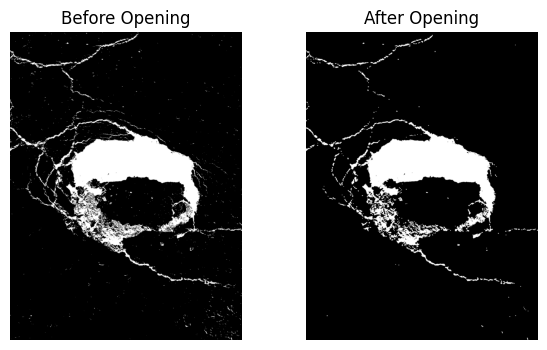

In [82]:
def opening(image, kernel):

    eroded = erosion(image, kernel) #lakukan erosi

    opened = dilation(eroded, kernel) #hasil erosi dipakai lagi untuk dilatasi

    return opened

#Jalankan fungsi opening
opened_image = opening(
    segmented_image,
    structuring_element
)

plt.figure(figsize=(7, 4))

plt.subplot(1, 2, 1)
plt.imshow(segmented_image, cmap='gray')
plt.title("Before Opening")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(opened_image, cmap='gray')
plt.title("After Opening")
plt.axis("off")

plt.show()

##Closing

Closing merupakan kombinasi dilation yang dilanjutkan dengan erosion.
Tujuan utamanya adalah mengisi lubang kecil dan menutup celah pada objek.

Dilatasi ---> Erosi

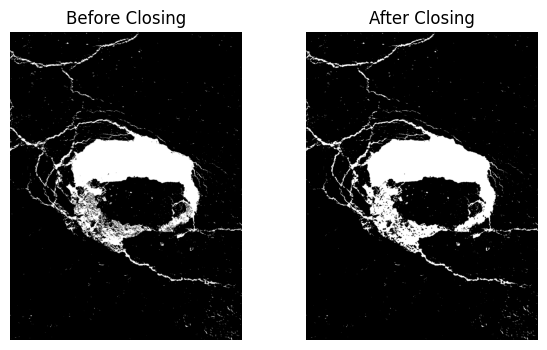

In [83]:
def closing(image, kernel):

    dilated = dilation(image, kernel) #Lakukan dilatasi dulu

    closed = erosion(dilated, kernel) #hasil dilatasi dipakai lagi untuk erosi

    return closed

#Panggil fungsi closing tadi
closed_image = closing(
    segmented_image,
    structuring_element
)

plt.figure(figsize=(7, 4))

plt.subplot(1, 2, 1)
plt.imshow(segmented_image, cmap='gray')
plt.title("Before Closing")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(closed_image, cmap='gray')
plt.title("After Closing")
plt.axis("off")

plt.show()

dilation memperbesar area putih sehingga lubang kecil dan celah dapat tertutup. Kemudian erosion mengembalikan ukuran objek agar tidak terlalu besar.

#Perbandingan Hasil

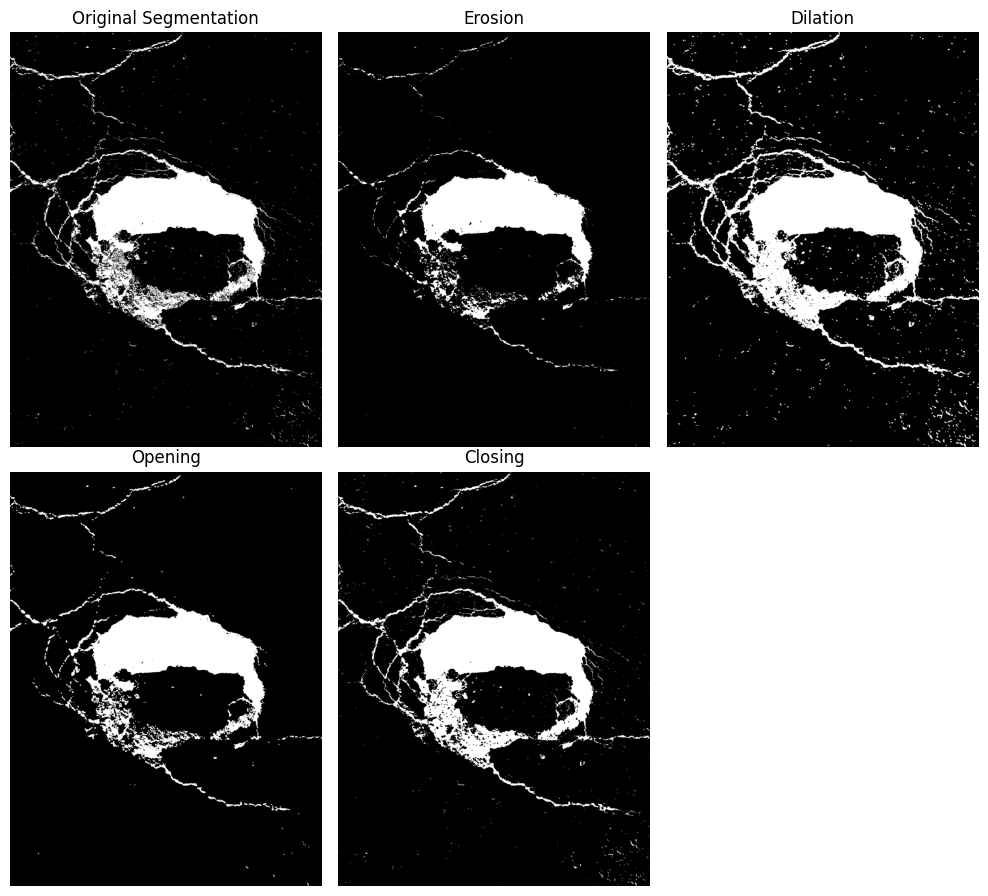

In [84]:
# Menampilkan perbandingan gambar

images = [
    segmented_image,
    eroded_image,
    dilated_image,
    opened_image,
    closed_image
]

titles = [
    "Original Segmentation",
    "Erosion",
    "Dilation",
    "Opening",
    "Closing"
]

plt.figure(figsize=(10, 9))

for i in range(len(images)):

    plt.subplot(2, 3, i+1)

    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()